# Session 1 - Scaling laws: a straight line through the animal kingdom

**AI in Quantitative Biology - practical 1 of 3 (90 min)**

An Asian elephant weighs about 200 000 times as much as a house mouse.
**How many times more energy does it burn?** Write your guess down now; we come back to it in Part 3.

Today's model has two parameters. We use it to learn what "fitting a model" means, how sure we
can be of a fitted number, and why the points that the model gets *wrong* are often the most
interesting ones.

| Part | Topic | Time |
|---|---|---|
| 1 | Meet the data | 10 min |
| 2 | The right axes | 10 min |
| 3 | Fitting a law | 20 min |
| 4 | Is the exponent 2/3 or 3/4? | 20 min |
| 5 | The residuals are the biology | 20 min |
| 6 | The pooling trap | 10 min |
| 7 | Your turn: other traits | homework |

✏️ marks exercises and ❓ questions to discuss with your neighbour: try them yourself first, the solution follows right after.

## Setup

Everything runs on a laptop CPU in seconds. The notebook expects the `data/` folder of the course
(it looks for it in the current folder and the folders above). On Google Colab, upload the `data/`
folder to your Drive in `MyDrive/AI_QBio/data` and run the cell below.

In [ ]:
# @title Setup: imports and data folder (run me)
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG = 0                                         # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)

import os
from pathlib import Path

def find_data_dir():
    "$QBIO_DATA if set, else a `data/` folder here or above, else Google Drive on Colab."
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "anage.tsv").exists():
            return p / "data"
    if "google.colab" in sys.modules:
        from google.colab import drive
        drive.mount("/content/drive")
        return Path("/content/drive/MyDrive/AI_QBio/data")
    raise FileNotFoundError("Cannot find the data/ folder: set QBIO_DATA to its path")

DATA_DIR = find_data_dir()
print("data from", DATA_DIR)

data from /home/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


## Part 1 - Meet the data

**AnAge** (Tacutu et al. 2018) is a curated database of life-history traits of animal species.
Our table has one row per species:

| column | meaning |
|---|---|
| `class`, `order`, `family`, `species`, `common_name` | taxonomy and names |
| `adult_mass_g` | typical adult body mass (g) |
| `longevity_yr` | **maximum** recorded lifespan (years) |
| `bmr_W` | basal metabolic rate (watts): the power used by a resting animal |
| `bmr_mass_g` | body mass of the animals in which `bmr_W` was measured (g) |
| `body_temp_K` | body temperature (kelvin) |
| `gestation_days`, `litter_size`, `female_maturity_days`, `birth_mass_g` | reproduction (used in the homework) |

Many cells are empty: nobody has measured the metabolic rate of most species.

In [ ]:
anage = pd.read_csv(DATA_DIR / "anage.tsv", sep="\t")
print(anage.shape)
anage.sample(5, random_state=RNG)

(3663, 14)


,class,order,family,species,common_name,adult_mass_g,longevity_yr,bmr_W,bmr_mass_g,body_temp_K,gestation_days,litter_size,female_maturity_days,birth_mass_g
935,Aves,Passeriformes,Parulidae,Leiothlypis peregrina,Tennessee warbler,8.50,6.4,NaN,NaN,NaN,11.0,6.0,365.0,1.34
117,Aves,Anseriformes,Anatidae,Anser fabalis,Bean goose,3348.00,25.6,NaN,NaN,NaN,28.0,4.0,1095.0,NaN
1043,Aves,Passeriformes,Ptilonorhynchidae,Sericulus chrysocephalus,Regent bowerbird,100.00,17.2,NaN,NaN,NaN,NaN,NaN,1454.0,NaN
2600,Mammalia,Rodentia,Cricetidae,Neotoma floridana,Eastern woodrat,291.00,8.6,NaN,NaN,NaN,33.0,3.5,95.0,13.43
2324,Mammalia,Notoryctemorphia,Notoryctidae,Notoryctes typhlops,Southern marsupial mole,53.25,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN


In [ ]:
anage.groupby("class")[["adult_mass_g", "longevity_yr", "bmr_W"]].count().sort_values("bmr_W", ascending=False).head(8)

,adult_mass_g,longevity_yr,bmr_W
class,,,
Mammalia,1337,1023,422
Aves,1491,1375,171
Amphibia,22,19,18
Reptilia,386,368,16
Cephalaspidomorphi,4,4,0
Chondrichthyes,57,57,0
Chondrostei,13,13,0
Coelacanthi,1,1,0


We start with the **mammals that have a metabolic rate**.

In [ ]:
mam = anage[anage["class"] == "Mammalia"].dropna(subset=["bmr_W", "bmr_mass_g"])
print(len(mam), "mammals with a metabolic rate")

422 mammals with a metabolic rate


✏️ **Exercise 1.1.**
1. Which are the lightest and the heaviest mammal in `mam`? *Hint:* `sort_values("bmr_mass_g")`.
2. Find the house mouse and the Asiatic elephant. What is the ratio of their masses, and of their
   metabolic rates? How good was your guess?

In [ ]:
cols = ["common_name", "bmr_mass_g", "bmr_W"]
print(mam.sort_values("bmr_mass_g")[cols].iloc[[0, -1]])

mouse = mam[mam["common_name"] == "House mouse"].iloc[0]
elephant = mam[mam["common_name"] == "Asiatic elephant"].iloc[0]
print(f"\nmass ratio      : {elephant['bmr_mass_g'] / mouse['bmr_mass_g']:,.0f}")
print(f"metabolic ratio : {elephant['bmr_W'] / mouse['bmr_W']:,.0f}")

                    common_name  bmr_mass_g     bmr_W
2920  White-toothed pygmy shrew   2.400e+00     0.063
2535           Asiatic elephant   3.672e+06  2336.500

mass ratio      : 204,000
metabolic ratio : 8,622


**Answer.** The elephant is about 204 000 times heavier but burns only about 8 600 times more
energy: a 2.3 kW heater against a 0.27 W one. Gram for gram, the mouse burns about 24 times more
than the elephant.

## Part 2 - The right axes

Always plot before fitting. The same data, twice:

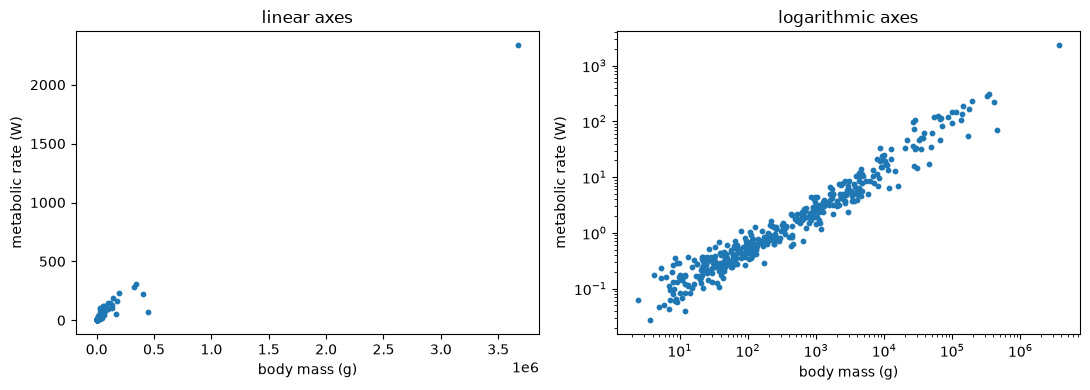

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(mam["bmr_mass_g"], mam["bmr_W"], s=10)
ax1.set_xlabel("body mass (g)"); ax1.set_ylabel("metabolic rate (W)"); ax1.set_title("linear axes")
ax2.scatter(mam["bmr_mass_g"], mam["bmr_W"], s=10)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("body mass (g)"); ax2.set_ylabel("metabolic rate (W)"); ax2.set_title("logarithmic axes")
plt.tight_layout()

❓ What do you see in each panel? Where are the 400 other mammals in the left panel?

**Answer.** On linear axes the elephant sets the scale and everything else is squeezed into the
corner: the plot shows one data point. On logarithmic axes each factor of 10 takes the same
space, from shrews to elephants, and the points fall along a **straight line**.

A straight line on log-log axes is a **power law**:

$$\log_{10} B = \log_{10} a + b \,\log_{10} M \qquad\Longleftrightarrow\qquad B = a\,M^{\,b}$$

The slope $b$ is the **scaling exponent**. It says how the metabolic rate $B$ changes when the mass
$M$ is multiplied by a factor: 10 times the mass gives $10^b$ times the metabolic rate.

## Part 3 - Fitting a law

"Fitting" means choosing $a$ and $b$ so that the line passes as close as possible to the points.
Least squares minimises the sum of squared vertical distances, here measured in $\log_{10}$ units.
We work with the logarithms from now on.

B = 0.0213 * M^0.709      R2 = 0.950


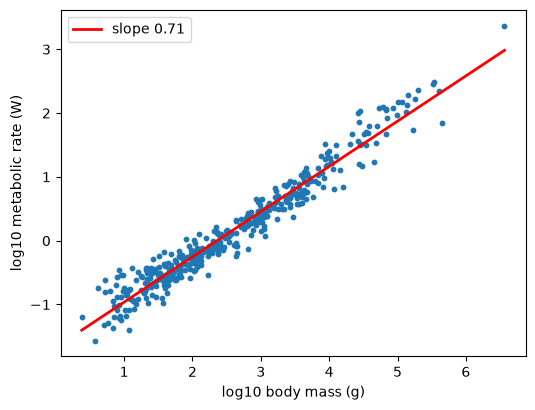

In [ ]:
x = np.log10(mam["bmr_mass_g"].values)
y = np.log10(mam["bmr_W"].values)

b, log_a = np.polyfit(x, y, 1)                  # slope and intercept of the best line
pred = log_a + b * x
r2 = 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)
print(f"B = {10 ** log_a:.4f} * M^{b:.3f}      R2 = {r2:.3f}")

xx = np.linspace(x.min(), x.max(), 50)
plt.figure(figsize=(6, 4.5))
plt.scatter(x, y, s=10)
plt.plot(xx, log_a + b * xx, "r", lw=2, label=f"slope {b:.2f}")
plt.xlabel("log10 body mass (g)"); plt.ylabel("log10 metabolic rate (W)"); plt.legend();

One line with two numbers describes 422 species over five orders of magnitude of body mass, with
R² = 0.95. This is **Kleiber's law** (1932).

✏️ **Exercise 3.1.** Use the fitted law to answer:
1. The elephant is 204 000 times heavier than the mouse. What ratio of metabolic rates does the
   law predict? Compare with the measured ratio of Exercise 1.1.
2. What does the law predict for a 70 kg mammal? The table has a measured value for humans.

In [ ]:
print(f"1. predicted ratio: {204_000 ** b:,.0f}")
print(f"2. 70 kg mammal: {10 ** (log_a + b * np.log10(70_000)):.0f} W predicted,",
      f"human measured: {mam.loc[mam['common_name'] == 'Human', 'bmr_W'].iloc[0]:.0f} W")

1. predicted ratio: 5,822
2. 70 kg mammal: 58 W predicted, human measured: 83 W


**Answer.** The law predicts a ratio of about 5 800, the measurement says 8 600: right within a
factor of 1.5, starting from a factor of 204 000. A 70 kg mammal should burn about 58 W; a resting
human burns about 83 W, a bright light bulb.

❓ The exponent is smaller than 1. What does that mean for one gram of mouse compared with one
gram of elephant? What would an exponent of exactly 1 mean?

**Answer.** With $b = 1$ every gram of tissue would burn the same power in every animal. With
$b \approx 0.71$ the power per gram falls as $M^{-0.29}$: big animals run "slower" per unit of
mass. Heart rate, breathing rate and many other rates follow the same trend.

## Part 4 - Is the exponent 2/3 or 3/4?

Two theories compete for the exponent:

* **2/3**: heat is lost through the body surface, and surface grows as $M^{2/3}$.
* **3/4**: energy is distributed by branching networks (blood vessels), whose geometry gives
  $M^{3/4}$ (West, Brown and Enquist 1997).

We found 0.71, in between. Before picking a side we need to know **how precisely** the data fix
the slope. With other species in the table we would have found a slightly different number.

The **bootstrap** imitates this: draw 422 species *with replacement* from our 422, refit, and
repeat many times. The spread of the refitted slopes estimates the uncertainty of ours.

slope 0.709, 95% interval 0.688 - 0.728


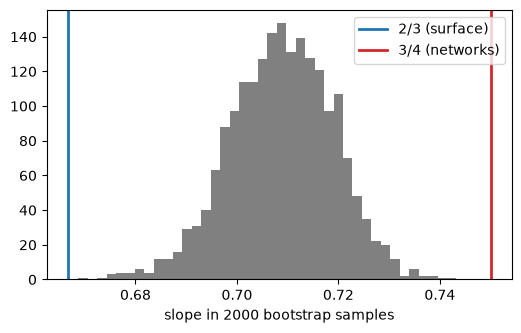

In [ ]:
rng = np.random.default_rng(RNG)
slopes = []
for _ in range(2000):
    i = rng.integers(0, len(x), len(x))         # resample species with replacement
    slopes.append(np.polyfit(x[i], y[i], 1)[0])
lo, hi = np.percentile(slopes, [2.5, 97.5])
print(f"slope {b:.3f}, 95% interval {lo:.3f} - {hi:.3f}")

plt.figure(figsize=(6, 3.5))
plt.hist(slopes, bins=40, color="grey")
plt.axvline(2 / 3, color="C0", lw=2, label="2/3 (surface)")
plt.axvline(3 / 4, color="C3", lw=2, label="3/4 (networks)")
plt.xlabel("slope in 2000 bootstrap samples"); plt.legend();

❓ Which theory wins?

**Answer.** Neither: the interval (0.69 - 0.73) excludes both 2/3 and 3/4. With 422 species the
slope is known to about ±0.02, and that is precise enough to reject both textbook values.

A confidence interval answers "how much would this number change with another sample?". It does
**not** answer "is a straight line the right model?". For that we look at what the line leaves
behind: the **residuals**, measured minus predicted.

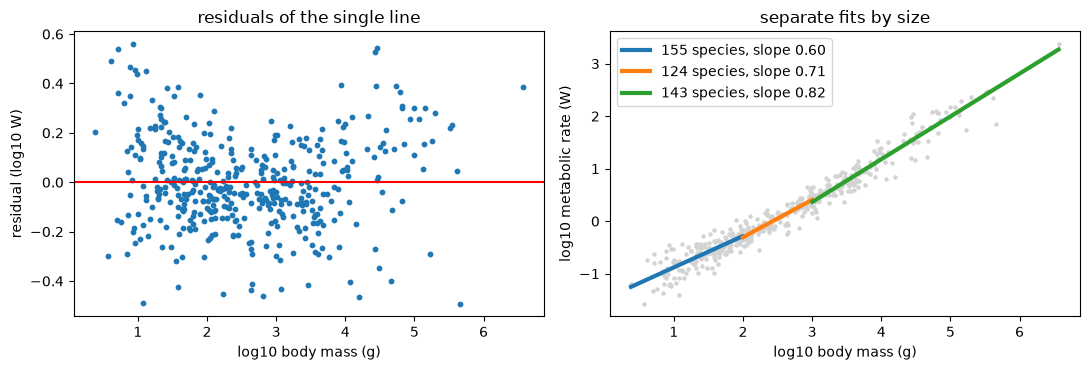

In [ ]:
resid = y - (log_a + b * x)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.scatter(x, resid, s=10)
ax1.axhline(0, color="r")
ax1.set_xlabel("log10 body mass (g)"); ax1.set_ylabel("residual (log10 W)"); ax1.set_title("residuals of the single line")

ranges = [(0, 2), (2, 3), (3, 7)]               # below 100 g, 100 g - 1 kg, above 1 kg
for a_, b_ in ranges:
    k = (x >= a_) & (x < b_)
    s, c = np.polyfit(x[k], y[k], 1)
    seg = np.array([x[k].min(), x[k].max()])
    ax2.plot(seg, c + s * seg, lw=3, label=f"{k.sum()} species, slope {s:.2f}")
ax2.scatter(x, y, s=5, color="lightgrey", zorder=0)
ax2.set_xlabel("log10 body mass (g)"); ax2.set_ylabel("log10 metabolic rate (W)"); ax2.set_title("separate fits by size")
ax2.legend(); plt.tight_layout()

❓ What do the residuals show? What happens to the slope from small to large mammals?

**Answer.** The residuals are positive at both ends and negative in the middle: the data bend
upwards. Fitted separately, small mammals give a slope near 0.60, medium ones 0.71 and large ones
0.82. The "law" is a very good summary, not an exact truth, and the exponent you measure depends on
which animals you put in the table. Much of the 2/3-against-3/4 debate comes from this
(Kolokotrones et al. 2010).

✏️ **Exercise 4.1.** Repeat the fit and the bootstrap for **birds** (`class == "Aves"`). Is their
exponent compatible with 2/3? With 3/4?

In [ ]:
birds = anage[anage["class"] == "Aves"].dropna(subset=["bmr_W", "bmr_mass_g"])
xb, yb = np.log10(birds["bmr_mass_g"].values), np.log10(birds["bmr_W"].values)
slopes_b = []
for _ in range(2000):
    i = rng.integers(0, len(xb), len(xb))
    slopes_b.append(np.polyfit(xb[i], yb[i], 1)[0])
print(f"{len(birds)} birds: slope {np.polyfit(xb, yb, 1)[0]:.3f},",
      "95% interval {:.3f} - {:.3f}".format(*np.percentile(slopes_b, [2.5, 97.5])))

171 birds: slope 0.655, 95% interval 0.635 - 0.674


**Answer.** Birds give 0.65 (0.64 - 0.67): compatible with 2/3, not with 3/4. Mammals and birds do
not even agree with each other.

## Part 5 - The residuals are the biology

Big animals live longer. Is there a law for lifespan too? We take all mammals with an adult mass
and a maximum longevity.

1023 mammals: longevity = 4.7 yr * M^0.159     R2 = 0.498


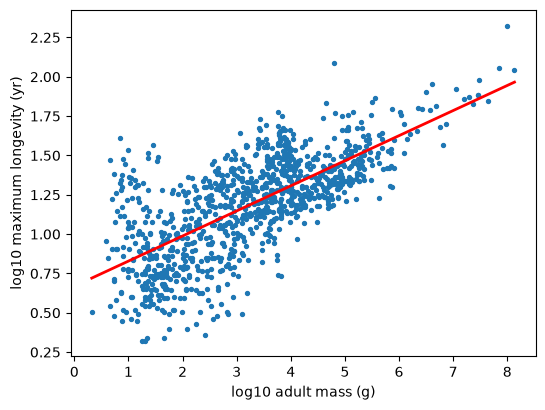

In [ ]:
life = anage[anage["class"] == "Mammalia"].dropna(subset=["adult_mass_g", "longevity_yr"]).copy()
xl = np.log10(life["adult_mass_g"].values)
yl = np.log10(life["longevity_yr"].values)

bl, cl = np.polyfit(xl, yl, 1)
life["predicted_yr"] = 10 ** (cl + bl * xl)
life["residual"] = yl - (cl + bl * xl)
r2l = 1 - np.sum(life["residual"] ** 2) / np.sum((yl - yl.mean()) ** 2)
print(f"{len(life)} mammals: longevity = {10 ** cl:.1f} yr * M^{bl:.3f}     R2 = {r2l:.3f}")

plt.figure(figsize=(6, 4.5))
plt.scatter(xl, yl, s=8)
plt.plot([xl.min(), xl.max()], [cl + bl * xl.min(), cl + bl * xl.max()], "r", lw=2)
plt.xlabel("log10 adult mass (g)"); plt.ylabel("log10 maximum longevity (yr)");

The trend is there (exponent 0.16) but the cloud is wide: R² is only 0.50. A residual of +0.3
means living $10^{0.3} \approx 2$ times longer than the line predicts for that size.

The model is the same for everybody, so the residual tells us **who is special**.

In [ ]:
cols = ["common_name", "order", "adult_mass_g", "longevity_yr", "predicted_yr", "residual"]
by_res = life.sort_values("residual")[cols]
pd.concat([by_res.head(5), by_res.tail(8)])

,common_name,order,adult_mass_g,longevity_yr,predicted_yr,residual
2537,Bennett's chinchilla rat,Rodentia,265.50,2.3,11.364,-0.694
2326,Long-nosed echymipera,Peramelemorphia,1250.00,3.1,14.548,-0.671
2189,Water opossum (yapok),Didelphimorphia,700.00,3.1,13.264,-0.631
2195,Lutrine opossum,Didelphimorphia,370.00,2.9,11.982,-0.616
2333,Raffray's bandicoot,Peramelemorphia,675.00,3.2,13.187,-0.615
2097,Daubenton's bat,Chiroptera,8.50,28.0,6.565,0.630
2094,Lesser mouse-eared bat,Chiroptera,23.00,33.0,7.694,0.632
2486,Human,Primates,62035.00,122.5,27.115,0.655
2125,Brown big-eared bat,Chiroptera,7.80,30.0,6.475,0.666
2105,Mouse-eared bat,Chiroptera,28.55,37.1,7.964,0.668


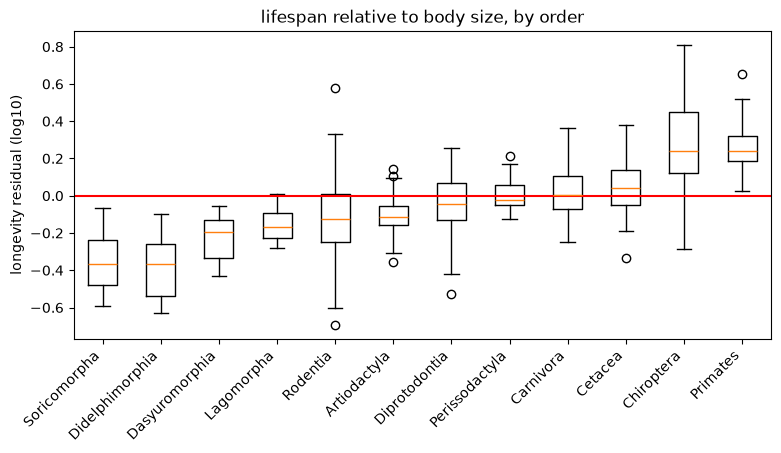

In [ ]:
big = life.groupby("order").filter(lambda d: len(d) >= 10)
order_rank = big.groupby("order")["residual"].median().sort_values().index
plt.figure(figsize=(9, 4))
plt.boxplot([big.loc[big["order"] == o, "residual"] for o in order_rank])
plt.axhline(0, color="r")
plt.xticks(range(1, len(order_rank) + 1), order_rank, rotation=45, ha="right")
plt.ylabel("longevity residual (log10)"); plt.title("lifespan relative to body size, by order");

✏️ **Exercise 5.1.** What lifespan does the law predict for a mammal of human size? How many
times longer than predicted do humans live? And Brandt's bat?

In [ ]:
life.loc[life["common_name"].isin(["Human", "Brandt's bat"]),
         ["common_name", "adult_mass_g", "longevity_yr", "predicted_yr"]].assign(
             ratio=lambda d: d["longevity_yr"] / d["predicted_yr"])

,common_name,adult_mass_g,longevity_yr,predicted_yr,ratio
2095,Brandt's bat,7.0,41.0,6.364,6.442
2486,Human,62035.0,122.5,27.115,4.518


**Answer.** A 62 kg mammal "should" live about 27 years; the human record is 122, 4.5 times more.
Brandt's bat weighs 7 g, should live about 6 years, and one was recaptured after 41.

❓ Bats (Chiroptera) and primates sit above the line, opossums and shrews below. Can you think of
reasons? And is the human value comparable with the others?

**Answer.** A common explanation is the risk of being eaten. Animals that escape predators (by
flying, living in trees, being clever or social) can benefit from investing in a durable body;
for a shrew or an opossum, which rarely survives two years in the wild anyway, it does not pay.
The fitted line told us nothing of this, but its residuals pointed straight at the question.

On the second point, be careful: "maximum longevity" is the record among the individuals observed.
For humans that is billions of people with birth certificates, for most species a few zoo
animals. A record grows with the number of individuals looked at, so part of the human residual is
an effect of how the data were collected.

## Part 6 - The pooling trap

Back to metabolic rate, now with **all** animals that have a measurement: mammals, birds, reptiles
and amphibians.

one line for all 627 species: slope 0.713, R2 = 0.819


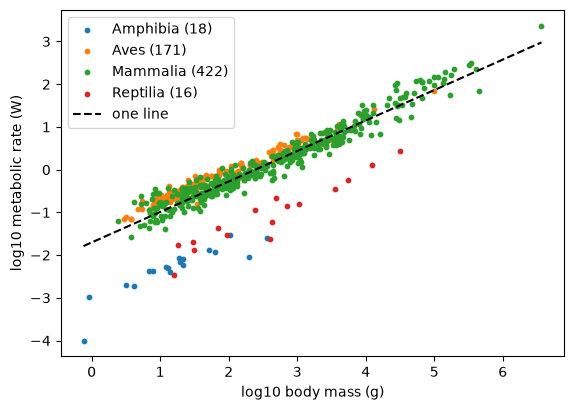

In [ ]:
allb = anage.dropna(subset=["bmr_W", "bmr_mass_g"])
xa, ya = np.log10(allb["bmr_mass_g"].values), np.log10(allb["bmr_W"].values)

ba, ca = np.polyfit(xa, ya, 1)
r2a = 1 - np.sum((ya - ca - ba * xa) ** 2) / np.sum((ya - ya.mean()) ** 2)
print(f"one line for all {len(allb)} species: slope {ba:.3f}, R2 = {r2a:.3f}")

plt.figure(figsize=(6.5, 4.5))
for cls, d in allb.groupby("class"):
    plt.scatter(np.log10(d["bmr_mass_g"]), np.log10(d["bmr_W"]), s=10, label=f"{cls} ({len(d)})")
plt.plot([xa.min(), xa.max()], [ca + ba * xa.min(), ca + ba * xa.max()], "k--", label="one line")
plt.xlabel("log10 body mass (g)"); plt.ylabel("log10 metabolic rate (W)"); plt.legend();

With more data, R² fell from 0.95 to 0.82. The plot shows why: there are two bands. We let each
class have its own intercept and keep one common slope:

In [ ]:
from sklearn.linear_model import LinearRegression

dummies = pd.get_dummies(allb["class"]).astype(float)       # one 0/1 column per class
Xa = np.column_stack([xa, dummies.values])
lin = LinearRegression(fit_intercept=False).fit(Xa, ya)
print(f"common slope {lin.coef_[0]:.3f}, R2 = {lin.score(Xa, ya):.3f}")
offsets = pd.Series(lin.coef_[1:], index=dummies.columns)
print("\nmetabolic rate relative to a mammal of the same mass:")
print((10 ** (offsets - offsets["Mammalia"])).round(2))

common slope 0.700, R2 = 0.961

metabolic rate relative to a mammal of the same mass:
Amphibia    0.03
Aves        1.54
Mammalia    1.00
Reptilia    0.06
dtype: float64


❓ What is the biology behind the two bands?

**Answer.** Mammals and birds keep their body warm, reptiles and amphibians do not. At equal mass a
reptile burns roughly 6% of what a mammal burns, an amphibian 3%. The exponent is the same (0.70); what differs is
the prefactor. One categorical variable brings R² back to 0.96.

✏️ **Exercise 6.1.** A careless dataset contains only **cold-blooded animals and mammals heavier
than 10 kg**. Fit one line to it. What exponent would its authors report?

In [ ]:
cold = allb["class"].isin(["Reptilia", "Amphibia"])
careless = allb[cold | ((allb["class"] == "Mammalia") & (allb["bmr_mass_g"] > 10_000))]
bc = np.polyfit(np.log10(careless["bmr_mass_g"]), np.log10(careless["bmr_W"]), 1)[0]
print(f"{len(careless)} species, slope {bc:.2f}")

83 species, slope 1.11


**Answer.** About 1.1, far above any slope inside a group: read naively, big animals would burn *more* per gram than small ones. The small animals of this table
are cold-blooded and the large ones warm-blooded, so the line joins the two bands and mixes the
effect of size with the effect of body temperature. A trend across groups can be very different
from the trend within each group (*Simpson's paradox*). Colour your points by group before
trusting a slope.

## Summary

* On the right axes, 422 mammals over five orders of magnitude follow $B = a\,M^{0.71}$.
  A model with **two parameters** reaches R² = 0.95.
* The **bootstrap** tells how precisely a fitted number is known (±0.02 here). It does not tell
  whether the model is right: the residuals do, and they show that the line is slightly bent.
* **Residuals are data.** Bats and primates live several times longer than their size predicts.
* **Pooling** groups that differ (warm- and cold-blooded) can hide a law or invent one.

In session 2 we give the same data to models with thousands of parameters, and ask what they can
do that the law cannot, and the reverse.

## Part 7 - Your turn: other traits (homework)

Many biological *times* are said to scale as $M^{1/4}$, so that all mammals get about the same
number of heartbeats in a life.

✏️ For mammals, fit the exponent against `adult_mass_g` of `gestation_days`,
`female_maturity_days`, `litter_size` and `birth_mass_g`. Which exponents are close to 1/4? Pick
one trait, list the species with the largest residuals, and propose an explanation.

In [ ]:
mammals = anage[anage["class"] == "Mammalia"]
rows = []
for trait in ["longevity_yr", "gestation_days", "female_maturity_days", "litter_size", "birth_mass_g"]:
    d = mammals.dropna(subset=[trait, "adult_mass_g"])
    xt, yt = np.log10(d["adult_mass_g"]), np.log10(d[trait])
    rows.append({"trait": trait, "n": len(d), "exponent": np.polyfit(xt, yt, 1)[0],
                 "R2": np.corrcoef(xt, yt)[0, 1] ** 2})
pd.DataFrame(rows)

,trait,n,exponent,R2
0,longevity_yr,1023,0.159,0.498
1,gestation_days,1102,0.206,0.506
2,female_maturity_days,1019,0.209,0.466
3,litter_size,1239,-0.103,0.251
4,birth_mass_g,851,0.913,0.782


**Answer.** Gestation and age at maturity scale with exponents near 0.21, longevity with 0.16: all
positive and below 1/4, with R² around 0.5. Birth mass scales almost in proportion to adult mass
(0.91), and litter size decreases slowly with size (-0.10). "Quarter-power scaling" is a useful
rule of thumb for times, not a precise law. For the residuals of gestation, look at marsupials:
they are born after a few weeks and complete their development in the pouch.